<!--

    Gaia Data Processing and Analysis Consortium (DPAC) 
    Co-ordination Unit 9 Work Package 930
    
    (c) 2005-2025 Gaia DPAC
    
    This program is free software: you can redistribute it and/or modify
    it under the terms of the GNU General Public License as published by
    the Free Software Foundation, either version 3 of the License, or
    (at your option) any later version.

    This program is distributed in the hope that it will be useful,
    but WITHOUT ANY WARRANTY; without even the implied warranty of
    MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the
    GNU General Public License for more details.

    You should have received a copy of the GNU General Public License
    along with this program.  If not, see <https://www.gnu.org/licenses/>.
    -->
    
This notebook illustrates a simple usage of cross-matched survey data available on the platform. It uses Gaia catalogue data (parallaxes and optical photometry) along with cross-matched infrared photometry to plot a de-reddened optical/infrared colour-absolute magnitude diagram (CAMD, a.k.a. an observational Hertzsprung-Russell diagram) of all sources with appropriate measurements.

Please note:
* only PanSTARRS DR1, 2MASS Point Sources and ALLWISE _cross-matches_ are hosted on this platform;
* cross-matched data consist of the 'best' neighbour (where that exists) along with original catalogue records (all columns) from the cross-matched survey; 
* if an external survey source has no Gaia cross-match counterpart then it does not exist here;
* the best neighbour and external catalogue records are concatenated into single rows in the cross-matched resources presented here.


In [ ]:
from pathlib import Path
import os

In [1]:
# Set up Dask
import dask.dataframe as dd
from dask.distributed import Client
c = Client('tcp://simple-scheduler.dask-operator.svc.cluster.local:8786')
print(c)

<Client: 'tcp://192.168.143.138:8786' processes=10 threads=60, memory=250.00 GiB>


/usr/local/lib/python3.10/site-packages/distributed/client.py:1612: VersionMismatchWarning: Mismatched versions found

+---------+-----------------+-----------------+-----------------+
| Package | Client          | Scheduler       | Workers         |
+---------+-----------------+-----------------+-----------------+
| lz4     | 4.4.4           | 4.3.3           | 4.3.3           |
| numpy   | 2.2.6           | 2.2.2           | 2.2.2           |
| python  | 3.10.16.final.0 | 3.10.12.final.0 | 3.10.12.final.0 |
| toolz   | 1.0.0           | 0.12.0          | 0.12.0          |
| tornado | 6.4.1           | 6.4.2           | 6.4.2           |
+---------+-----------------+-----------------+-----------------+
  warnings.warn(version_module.VersionMismatchWarning(msg[0]["warning"]))


In [13]:
import math

# range and resolution of the rasterized colour-magnitude diagram - configure to suit
brightest_abs_mag = -5.0
faintest_abs_mag = 15.0
bluest_colour = -2.0
reddest_colour = +6.0
mag_resolution = 0.02

# global constant given the above configuration
abs_mag_range = faintest_abs_mag - brightest_abs_mag
colour_range = reddest_colour - bluest_colour
xmax_idx = int((colour_range) / mag_resolution)
ymax_idx = int((abs_mag_range) / mag_resolution)

# raster function
def cmd_raster_index(magnitude, colour, parallax):
    '''
    Vectorized computation of a unique raster index in 2D absolute magnitude / colour space.
    '''
    # Distance modulus and absolute magnitude
    mmm = 5.0 * np.log10(1000.0 / parallax) - 5.0
    abs_mag = magnitude - mmm

    # Compute x and y indices (binning)
    xidx = np.round((colour - bluest_colour) * xmax_idx / colour_range).astype(int)
    yidx = np.round((abs_mag - brightest_abs_mag) * ymax_idx / abs_mag_range).astype(int)

    # Mask out-of-bound values (raster index = 0 if out of range)
    valid = (xidx >= 0) & (xidx < xmax_idx) & (yidx >= 0) & (yidx < ymax_idx)
    raster_idx = np.where(valid, xidx + xmax_idx * yidx, 0)

    return raster_idx


# define vectorized functions that reverse the encoded raster index into colour and absolute magnitude
# based on the same configuration
import numpy as np

def xidx(ridx_array: np.array) -> np.array:
    '''
    Given the vector raster index compute the x (colour) indices of the bins.
    '''
    return np.mod(ridx_array, xmax_idx)

def yidx(ridx_array: np.array) -> np.array:
    '''
    Given the vector raster index compute the y (absolute magnitude) indices of the bins.
    '''
    return np.trunc(ridx_array / xmax_idx).astype(int)



In [15]:
def process_partition(part1, part2):

    part1 = part1[
        (part1["ruwe"] < 1.4) &
        (part1["parallax_over_error"] > 10.0) &
        (part1["ag_gspphot"].notnull())
    ]
    part2 = part2[part2["k_m"].notnull()]

    merged = part1.merge(part2, how="inner", on="source_id")

    merged["ridx"] = cmd_raster_index(
        merged["phot_g_mean_mag"] - merged["ag_gspphot"],
        merged["phot_g_mean_mag"] - merged["ag_gspphot"] - merged["k_m"],
        merged["parallax"]
    )

    return merged[merged["ridx"] >= 0][["ridx"]]



In [ ]:
gaia_source = dd.read_parquet(Path(os.environ['DASK_DATA_PATH_GAIA_DR3_SSD']).joinpath("GDR3_GAIA_SOURCE"))
tmasspsc = dd.read_parquet(Path(os.environ['DASK_DATA_PATH_GAIA_DR3_SSD']).joinpath("GDR3_2MASSPSC_BEST_NEIGHBOURS"))

In [32]:
df = dd.map_partitions(
    process_partition,
    gaia_source,
    tmasspsc,
    align_dataframes=False,
    meta={"ridx": "int64"}
).groupby("ridx").size().reset_index().rename(columns={0: "count_in_pixel"})


In [33]:
from IPython.display import display

# collect the counts as a Pandas data frame
pdf = df.compute()
# ... this will action the distributed spark job and then merge the individual worker aggregations.
# It "collects" all the data to the driver executor as a monolithic in-memory data set - always use with care!

# compute the colour/magnitude bin centres from the raster index via vectorized functions defined above
#pdf['colour'] = colours(pdf['ridx'].values)
#pdf['abs_mag'] = abs_mags(pdf['ridx'].values)
pdf['xidx'] = xidx(pdf['ridx'].values)
pdf['yidx'] = yidx(pdf['ridx'].values)

# quick-look sanity check (and optional download of results set)
display(pdf)

,ridx,count_in_pixel,xidx,yidx
0,56601,159,201,141
1,63323,9,123,158
2,79401,304,201,198
3,92885,90,85,232
4,104977,557,177,262
...,...,...,...,...
1527,145891,1,291,364
1528,24856,1,56,62
1529,370739,1,339,926
1530,234385,1,385,585


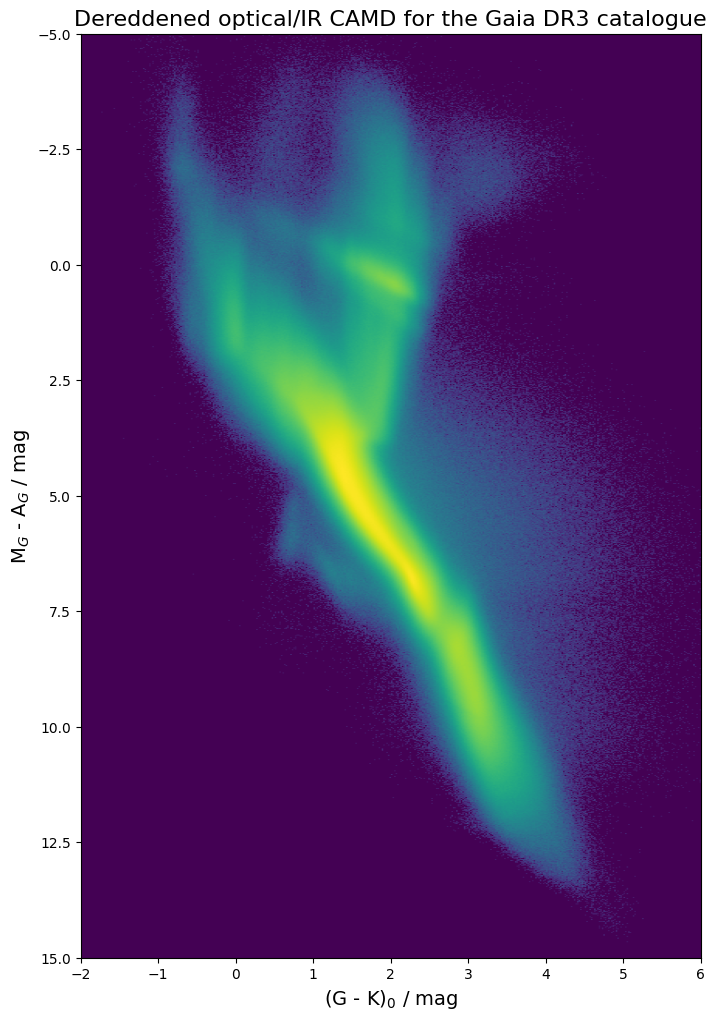

In [34]:
import matplotlib.pyplot as plot

# create a sparse array object for the results (only those elements with non-zero counts are in the results set)
from scipy.sparse import coo_matrix # renamed coo_array in later versions of scipy
# https://docs.scipy.org/doc/scipy-1.6.3/reference/generated/scipy.sparse.coo_matrix.html#scipy.sparse.coo_matrix
sparse_data = coo_matrix((np.log(pdf['count_in_pixel']), (pdf['yidx'], pdf['xidx'])), shape = (ymax_idx, xmax_idx))
# ... use logged counts to enhance low-level features in the CAMD

# expand into a dense array in order to plot as an image with imshow
dense_data = sparse_data.todense()

# do the plot
plot.figure(0, figsize = (8.0, 12.0))
plot.title('Dereddened optical/IR CAMD for the Gaia DR3 catalogue', fontsize = 16)
plot.xlabel('(G - K)$_0$ / mag', fontsize = 14)
plot.ylabel('M$_G$ - A$_G$ / mag', fontsize = 14)
plot.imshow(dense_data, aspect = 'auto', 
    extent = [bluest_colour, bluest_colour + xmax_idx * mag_resolution, brightest_abs_mag + ymax_idx * mag_resolution, brightest_abs_mag])

* [Gaia data release cross-matches](https://gea.esac.esa.int/archive/documentation/GDR3/Catalogue_consolidation/chap_crossmatch/)
* [2MASS PSC](https://irsa.ipac.caltech.edu/data/2MASS/docs/releases/allsky/doc/sec2_2a.html "2MASS point-source catalogue column details")
* [ALLWISE](https://wise2.ipac.caltech.edu/docs/release/allwise/expsup/sec2_1a.html "ALLWISE catalogue column details")
* [PS1 OTMO](https://outerspace.stsci.edu/display/PANSTARRS/PS1+MeanObjectView+table+fields "PS1 DR1 object-thin object-mean catalogue column details") (note that column names follow the Gaia archive convention of all lower-case with underscore separators rather than the original CamelCase)
